In [7]:
import numpy as np
import cv2
import os
import zipfile
import matplotlib.pyplot as plt

Unzipping the zip files

In [8]:
def unzip(zip_path):
    with zipfile.ZipFile(zip_path,'r') as z:
        z.extractall()

unzip("Train.zip")
unzip("Test.zip")

In [9]:
IMG_SIZE = 64

def load_dataset(folder):

    X = []
    y = []

    classes = sorted(os.listdir(folder))

    for label,cls in enumerate(classes):

        class_path = os.path.join(folder,cls)

        if not os.path.isdir(class_path):
            continue

        for file in os.listdir(class_path):

            path = os.path.join(class_path,file)

            img = cv2.imread(path)

            if img is None:
                continue

            img = cv2.resize(img,(IMG_SIZE,IMG_SIZE))
            img = img/255.0

            X.append(img.flatten())
            y.append(label)

    return np.array(X),np.array(y),classes

In [12]:
X_train,y_train,classes = load_dataset("Train")
X_test,y_test,_ = load_dataset("Test")

print("Train:",X_train.shape)
print("Test:",X_test.shape)

Train: (4000, 12288)
Test: (1000, 12288)


One-Hot encoding

In [23]:
def one_hot(y,num_classes):

    out = np.zeros((len(y),num_classes))
    out[np.arange(len(y)),y] = 1

    return out

num_classes = len(classes)

y_train_oh = one_hot(y_train,num_classes)
print(y_train_oh)

[[1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 ...
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]]


He initialization
Here,we use Kaiming He initialization to initialize the weights so as to facilitate more efficient training by addressing the vanishing or exploding gradient problem and
potential overfitting that comes with using random initialization.

In [13]:
np.random.seed(0)

input_size = X_train.shape[1]
h1 = 256
h2 = 128
output = num_classes

W1 = np.random.randn(input_size,h1)*np.sqrt(2/input_size)
b1 = np.zeros((1,h1))

W2 = np.random.randn(h1,h2)*np.sqrt(2/h1)
b2 = np.zeros((1,h2))

W3 = np.random.randn(h2,output)*np.sqrt(2/h2)
b3 = np.zeros((1,output))

Activation function
Standard ReLU and softmax functions are used.

In [14]:
def relu(x):
    return np.maximum(0,x)

def relu_deriv(x):
    return x>0

def softmax(x):

    exp = np.exp(x-np.max(x,axis=1,keepdims=True))
    return exp/np.sum(exp,axis=1,keepdims=True)

Forward propagation

In [15]:
def forward(X):

    z_1 = X@W1 + b1
    a_1= relu(z_1)

    z_2 = a_1@W2 + b2
    a_2 = relu(z_2)

    z_3 = a_2@W3 + b3
    a_3 = softmax(z_3)

    cache = (z_1,a_1,z_2,a_2,z_3,a_3)

    return a_3,cache

Loss function
Cross-entropy loss function is used as it heavily penalizes confident wrong predictions.

In [16]:
def loss(Y,Yhat):

    m = Y.shape[0]

    return -np.sum(Y*np.log(Yhat+1e-9))/m

Backword propagation

In [17]:
def backward(X,Y,cache):

    z_1,a_1,z_2,a_2,z_3,a_3 = cache
    m = X.shape[0]

    dz_3 = a_3-Y
    dw_3 = a_2.T@dz_3/m
    db3 = np.sum(dz_3,axis=0,keepdims=True)/m

    da_2 = dz_3@W3.T
    dz_2 = da_2*relu_deriv(z_2)

    dw_2 = a_1.T@dz_2/m
    db2 = np.sum(dz_2,axis=0,keepdims=True)/m

    da_1 = dz_2@W2.T
    dz_1 = da_1*relu_deriv(z_1)

    dw_1 = X.T@dz_1/m
    db1 = np.sum(dz_1,axis=0,keepdims=True)/m

    return dw_1,db1,dw_2,db2,dw_3,db3

Mini-batch training method
Here,we use the mini-batch training method as it uses a small batch of samples from the dataset for training.
This leads to faster computation(as batches are smaller),less load on the memory,and more updates per epoch than BGD(4000/32=125 updates per epoch for the training set).
Small randomness in the batches also helps to escape poor local minima.

In [18]:
lr = 0.001
epochs = 40
batch_size = 32

losses = []

for epoch in range(epochs):

    perm = np.random.permutation(len(X_train))

    X_train = X_train[perm]
    y_train_oh = y_train_oh[perm]

    for i in range(0,len(X_train),batch_size):

        Xb = X_train[i:i+batch_size]
        Yb = y_train_oh[i:i+batch_size]

        yhat,cache = forward(Xb)

        dW1,db1,dW2,db2,dW3,db3 = backward(Xb,Yb,cache)

        W1[:] -= lr*dW1
        b1[:] -= lr*db1

        W2[:] -= lr*dW2
        b2[:] -= lr*db2

        W3[:] -= lr*dW3
        b3[:] -= lr*db3

    pred,_ = forward(X_train)
    l = loss(y_train_oh,pred)

    losses.append(l)

    print("Epoch",epoch,"Loss",l)

Epoch 0 Loss 0.9912841507794494
Epoch 1 Loss 0.7549059579787393
Epoch 2 Loss 0.6167136870955144
Epoch 3 Loss 0.5309957751609652
Epoch 4 Loss 0.46584048246966686
Epoch 5 Loss 0.41820306410498326
Epoch 6 Loss 0.38178241523429346
Epoch 7 Loss 0.35340015045063855
Epoch 8 Loss 0.32620146130114336
Epoch 9 Loss 0.30597570299245536
Epoch 10 Loss 0.2893331308682626
Epoch 11 Loss 0.2741231293877446
Epoch 12 Loss 0.2605025273147549
Epoch 13 Loss 0.24852922502857872
Epoch 14 Loss 0.23860372897328086
Epoch 15 Loss 0.23117747538966155
Epoch 16 Loss 0.22231637993542716
Epoch 17 Loss 0.21654713553434224
Epoch 18 Loss 0.20727265779356446
Epoch 19 Loss 0.20167964484879217
Epoch 20 Loss 0.1959034498051081
Epoch 21 Loss 0.19030876655414802
Epoch 22 Loss 0.18720646099198246
Epoch 23 Loss 0.1827341325865939
Epoch 24 Loss 0.17687098749868288
Epoch 25 Loss 0.17304312161929408
Epoch 26 Loss 0.16978240228156327
Epoch 27 Loss 0.16856935121097377
Epoch 28 Loss 0.16536642327314918
Epoch 29 Loss 0.16225133380755574

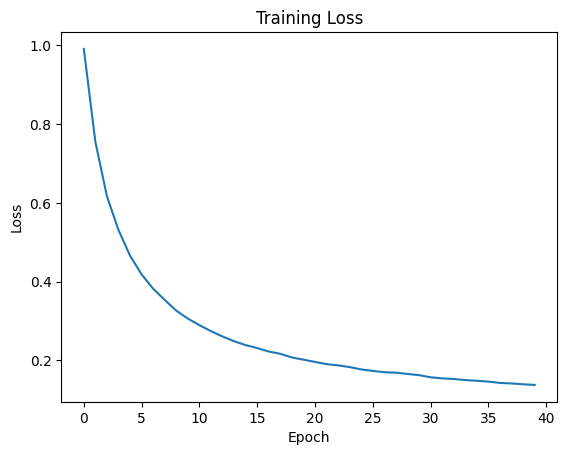

In [19]:
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()

Predict function

In [20]:
def predict(X):

    p,_ = forward(X)
    return np.argmax(p,axis=1)

Running the model on testing data

In [21]:
y_pred = predict(X_test)

accuracy = np.mean(y_pred==y_test)

print("Test Accuracy:",accuracy)

Test Accuracy: 0.95


Confusion matrix

In [22]:
num_classes = len(classes)

cm = np.zeros((num_classes,num_classes))

for t,p in zip(y_test,y_pred):
    cm[t][p]+=1

print("Confusion Matrix")
print(cm)

Confusion Matrix
[[199.   0.   0.   1.   0.]
 [  0. 184.   0.  16.   0.]
 [  0.   0. 192.   1.   7.]
 [  0.  12.   0. 188.   0.]
 [  0.   0.  13.   0. 187.]]
